In [6]:
%load_ext autoreload
%autoreload 2

In [7]:
from pylab import *
import numpy as np


In [148]:
#batch_frame_path = "C:\\Users\\ModeLabQBI\\LAB\\algorithms\\DigitalHolography\\data_testing\\Aligment_batch_frames_z=0_ref_BEST.npz"
batch_frame_path = "C:\\Users\\ModeLabQBI\\LAB\\algorithms\\DigitalHolography\\data_testing\\Aligment_batch_frames_SLM_relayed_modes.npz"

keys: ['frames']
frames (506, 640, 512) float32 min 0.0 max 2325.0


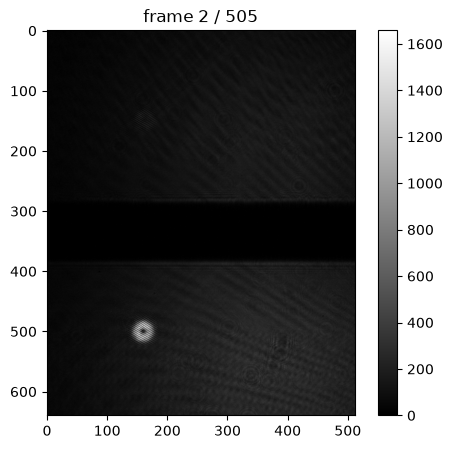

In [149]:
npz_path = batch_frame_path
with np.load(npz_path) as data:
    frames = data["frames"]
    print( "keys:", list(data.files))

print("frames", frames.shape, frames.dtype, "min", float(frames.min()), "max", float(frames.max()))

frame_index = 2
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(frames[frame_index], cmap="gray")
ax.set_title(f"frame {frame_index} / {frames.shape[0] - 1}")
fig.colorbar(image, ax=ax, fraction=0.046)
plt.show()

In [150]:
_batch_dim = frames.shape
num_frames = _batch_dim[0]
frame_width = _batch_dim[2]
frame_height = _batch_dim[1]
print(f'{num_frames} frames of {frame_width}x{frame_height} pixels (WxH)')

506 frames of 512x640 pixels (WxH)


In [151]:
from visualization import complexToRGB


# Digholo

In [152]:
from pathlib import Path
import sys

root = Path.cwd().resolve().parent
sys.path.insert(0, str(root))

from pyDigHolo import DigHolo

In [153]:
dh = DigHolo()

DigHolo has been destroyed


In [ ]:
512, 640

In [516]:
dh.setProps(PixelSize=20e-6, Wavelength=1310e-9, polCount=2, maxMG=22,
fftWindowSizeX =  128,
fftWindowSizeY =  128,
basisType = 0,
goalIdx = 0,
#FFTRadius = 0.8,
resolutionMode = 0,
verbosity=2)

In [517]:
dh.save_properties_to_json("relayed_modes_test_Cheetah_Xenics.json")

In [518]:
frames.dtype

dtype('float32')

In [519]:
frames_h = np.ascontiguousarray(np.transpose(frames, (0, 2, 1)))
#frames_h = flip(frames_h, axis=2)
coefs, metrics = dh.autoAlign(frames_h)

In [520]:
frames_h.shape

(506, 512, 640)

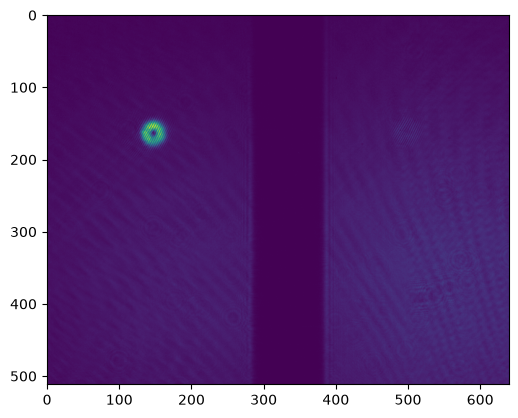

In [521]:
imshow(frames_h[3])

In [522]:
coefs_interleaved = zeros_like(coefs)

coefs_h = coefs[:, 0:coefs.shape[1]//2]
coefs_v = coefs[:, coefs.shape[1]//2:]

coefs_interleaved[:,::2] = coefs_h
coefs_interleaved[:,1::2] = coefs_v

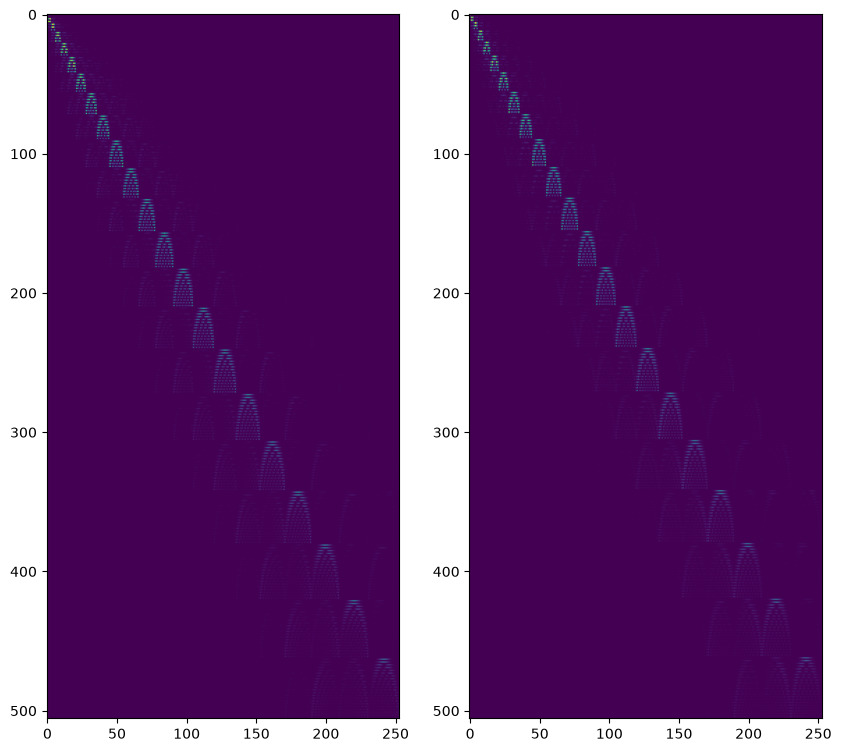

In [523]:
fig, ax = subplots(1,2, figsize=(10,10))
ax[0].imshow(abs(coefs_h)**2)
ax[1].imshow(abs(coefs_v)**2)

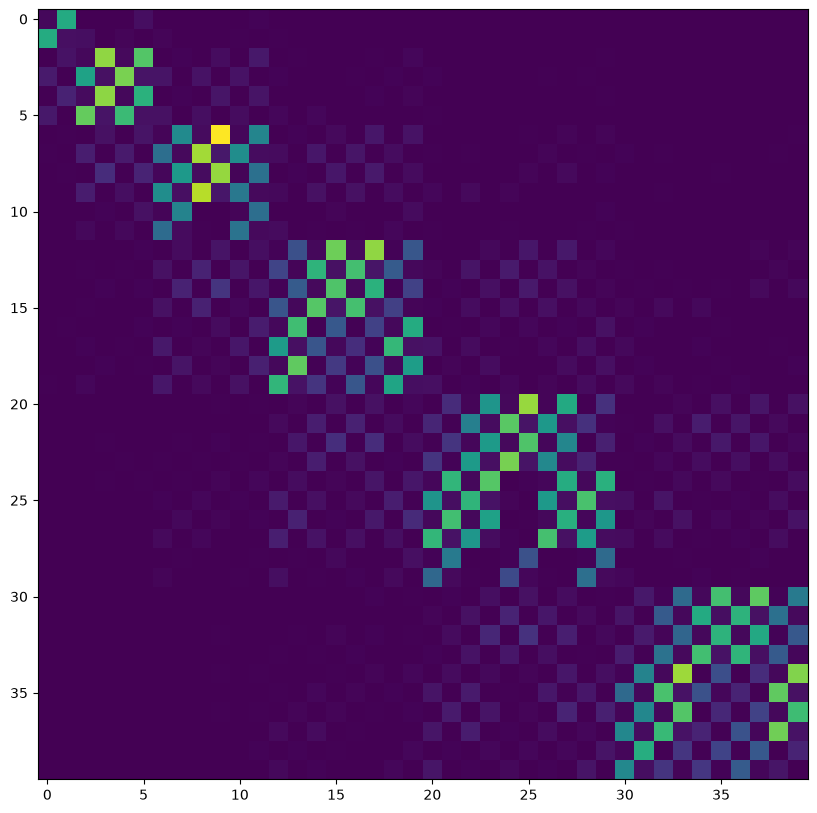

In [524]:
figure(figsize=(10,10))
imshow(abs(coefs_interleaved[0:40,0:40])**2)

In [533]:
coefs = dh.processBatch(frames_h[None, 1,...], batchCount=1)

In [534]:
fields = dh.getFields()

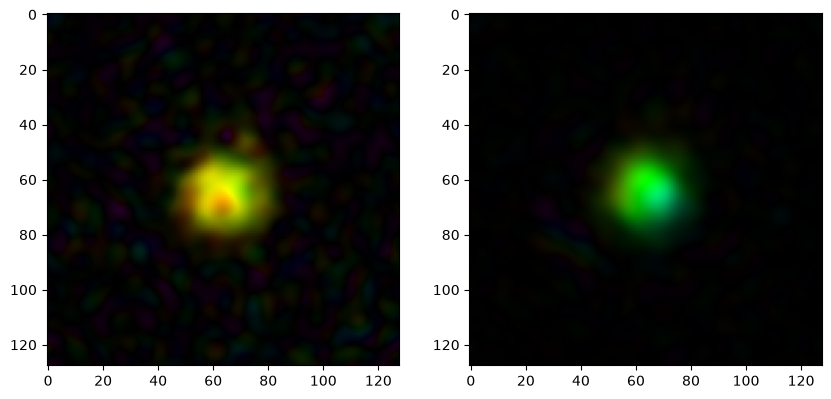

In [535]:
fig, ax = subplots(1,2, figsize=(10,10))
ax[0].imshow(complexToRGB(fields[0,1]))
ax[1].imshow(complexToRGB(fields[0,0]))


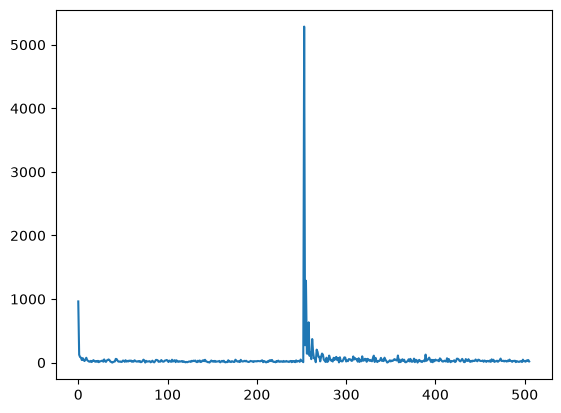

In [528]:
plot(abs(coefs[0]))

In [538]:
import ipywidgets as widgets

viewport_names = {
    1: "camera",
    2: "Fourier",
    3: "Fourier dB",
    4: "Fourier window",
    5: "Fourier window abs",
    6: "field",
    7: "field abs",
    8: "field from modes",
}

def show_viewport(viewport_idx, frame_index):
    dh.processBatch(frames_h[None, frame_index, ...], batchCount=1)
    img, metadata = dh.getViewPort(viewport_idx)
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(img)
    ax.set_title(
        f"frame {frame_index} / {frames_h.shape[0] - 1}   "
        f"viewport {viewport_idx}: {viewport_names[viewport_idx]}\n{metadata}"
    )
    plt.show()

widgets.interact(
    show_viewport,
    viewport_idx=widgets.IntSlider(min=1, max=8, step=1, value=1, continuous_update=False),
    frame_index=widgets.IntSlider(min=0, max=frames_h.shape[0] - 1, step=1, value=0, continuous_update=False),
)

interactive(children=(IntSlider(value=1, continuous_update=False, description='viewport_idx', max=8, min=1), I…

<function __main__.show_viewport(viewport_idx, frame_index)>

In [536]:
from matplotlib.patches import Circle
import ipywidgets as widgets

px = 20e-6
h, w = frames_h.shape[1:]

def show_frame(frame_index):
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(frames_h[frame_index], cmap="gray")
    for pol, color in (("PolH", "r"), ("PolV", "c")):
        col = dh._properties[f"BeamCentreX{pol}"] / px + (w - 1) / 2
        row = dh._properties[f"BeamCentreY{pol}"] / px + (h - 1) / 2
        radius = dh._properties[f"BasisWaist{pol}"] / px
        ax.plot(col, row, "+", color=color, ms=12)
        ax.add_patch(Circle((col, row), radius, fill=False, ec=color, lw=1.5))
    ax.set_title(f"frame {frame_index} / {frames_h.shape[0] - 1}")
    plt.show()

widgets.interact(show_frame, frame_index=(0, frames_h.shape[0] - 1, 1))

interactive(children=(IntSlider(value=252, description='frame_index', max=505), Output()), _dom_classes=('widg…

<function __main__.show_frame(frame_index)>